# M2 MALIA - Deep Learning
## Projet HAR : Étude progressive des réseaux de neurones
### Version 2 : Réseau Profond, Régularisation, Interprétabilité & Évaluation Finale

**Auteurs :** Madjiguène FALL & Alioune DIOP  
**Enseignant :** Walid Bechkit  
**Année universitaire :** 2026–2027

---
### Objectifs de cette Version 2 :
1. **Extension de l'architecture (Partie 3)** : Largeur (128, 256) et Profondeur (2 à 4 couches cachées), analyse du nombre de paramètres et du temps de calcul.
2. **Régularisation et robustesse (Partie 4)** : Dropout (p=0.1, 0.3, 0.5), Weight Decay (L2), Batch Normalization, et Early Stopping.
3. **Visualisation et Évaluation Finale (Partie 5)** : Courbes d'apprentissage, passage unique sur le test sanctuarisé, matrice de confusion et analyse physique des erreurs.
4. **Interprétabilité et Réduction de Dimension (Partie 6)** : Projections t-SNE de l'espace d'entrée brut vs espace latent de la dernière couche cachée.
5. **Ouverture / Bonus (Partie 7)** : Étude d'ablation par famille de capteurs.


## 1. Imports des bibliothèques


In [1]:
import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Import des fonctions modulaires partagées de src/
sys.path.append('../../src')
from data_loader import load_har_data, split_by_subject, prepare_features_and_labels, create_dataloaders

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 2. Chargement des Données et DataLoaders
Nous réutilisons le découpage validé par volontaires entiers (sujets 1, 3, 5, 7 pour la validation).


In [2]:
train_df, test_df = load_har_data('../../data/HAR')

# Découpage par volontaires
val_subjects = [1, 3, 5, 7]
train_split, val_split = split_by_subject(train_df, val_subjects=val_subjects)

# Séparation caractéristiques et cible
X_tr, y_tr, le, feature_cols = prepare_features_and_labels(train_split)
X_val, y_val, _, _ = prepare_features_and_labels(val_split, label_encoder=le)
X_test, y_test, _, _ = prepare_features_and_labels(test_df, label_encoder=le)

batch_size = 64
train_loader, val_loader = create_dataloaders(X_tr, y_tr, X_val, y_val, batch_size=batch_size)
_, test_loader = create_dataloaders(X_tr, y_tr, X_test, y_test, batch_size=batch_size)

print(f"Échantillons d'entraînement : {len(X_tr)}")
print(f"Échantillons de validation   : {len(X_val)}")
print(f"Échantillons de test final   : {len(X_test)}")
print(f"Classes d'activité           : {list(le.classes_)}")


Échantillons d'entraînement : 6054
Échantillons de validation   : 1298
Échantillons de test final   : 2947
Classes d'activité           : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


## 3. Définition de l'Architecture Profonde Modulaire (Partie 3 & 4)


In [3]:
class DeepMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dims=[128, 64], num_classes=6, 
                 activation='relu', dropout_p=0.0, use_bn=False):
        super().__init__()
        layers = []
        prev_dim = input_dim
        
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            if use_bn:
                layers.append(nn.BatchNorm1d(h_dim))
            if activation == 'relu':
                layers.append(nn.ReLU())
            elif activation == 'tanh':
                layers.append(nn.Tanh())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            prev_dim = h_dim
            
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(prev_dim, num_classes)
        
    def forward(self, x):
        feat = self.features(x)
        out = self.classifier(feat)
        return out
    
    def extract_features(self, x):
        """Extrait la représentation latente pour l'analyse t-SNE"""
        return self.features(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Vérification
m_check = DeepMLP(hidden_dims=[256, 128, 64], dropout_p=0.3, use_bn=True)
print(m_check)
print(f"Paramètres entraînables : {count_parameters(m_check):,}")


DeepMLP(
  (features): Sequential(
    (0): Linear(in_features=561, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
  )
  (classifier): Linear(in_features=64, out_features=6, bias=True)
)
Paramètres entraînables : 186,246


## 4. Fonctions d'Entraînement avec Early Stopping


In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x_b, y_b in dataloader:
        optimizer.zero_grad()
        out = model(x_b)
        loss = criterion(out, y_b)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x_b.size(0)
        correct += (out.argmax(dim=1) == y_b).sum().item()
        total += x_b.size(0)
    return total_loss / total, correct / total

def evaluate(model, dataloader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x_b, y_b in dataloader:
            out = model(x_b)
            loss = criterion(out, y_b)
            total_loss += loss.item() * x_b.size(0)
            all_preds.extend(out.argmax(dim=1).cpu().numpy())
            all_targets.extend(y_b.cpu().numpy())
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return total_loss / len(all_targets), acc, macro_f1, all_preds, all_targets

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=30, patience=6):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    best_loss = float('inf')
    best_state, patience_cnt = None, 0
    start = time.time()
    for ep in range(epochs):
        tr_l, tr_a = train_epoch(model, train_loader, criterion, optimizer)
        vl_l, vl_a, vl_f, _, _ = evaluate(model, val_loader, criterion)
        history['train_loss'].append(tr_l)
        history['val_loss'].append(vl_l)
        history['train_acc'].append(tr_a)
        history['val_acc'].append(vl_a)
        history['val_f1'].append(vl_f)
        if vl_l < best_loss:
            best_loss = vl_l
            patience_cnt = 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history, time.time() - start


## 5. Extension de l'Architecture : Largeur & Profondeur (Partie 3)


Architecture                      | Paramètres | Temps (s) | Val Loss | Val Acc (%) | Val F1 (%)
----------------------------------------------------------------------------------------
1 couche (64) [V1]                |     36,358 |      5.8s |   0.1346 |      96.07% |     95.88%
1 couche (128)                    |     72,710 |      9.6s |   0.1287 |      96.30% |     96.13%
1 couche (256)                    |    145,414 |      6.1s |   0.1310 |      95.69% |     95.48%
2 couches [128, 64]               |     80,582 |     13.0s |   0.1295 |      95.92% |     95.75%
3 couches [256, 128, 64] (ReLU)   |    185,414 |     11.4s |   0.1412 |      95.45% |     95.26%
3 couches [256, 128, 64] (Tanh)   |    185,414 |     16.0s |   0.1333 |      96.22% |     96.06%
4 couches [256, 128, 64, 32]      |    187,302 |      8.5s |   0.1580 |      95.45% |     95.23%


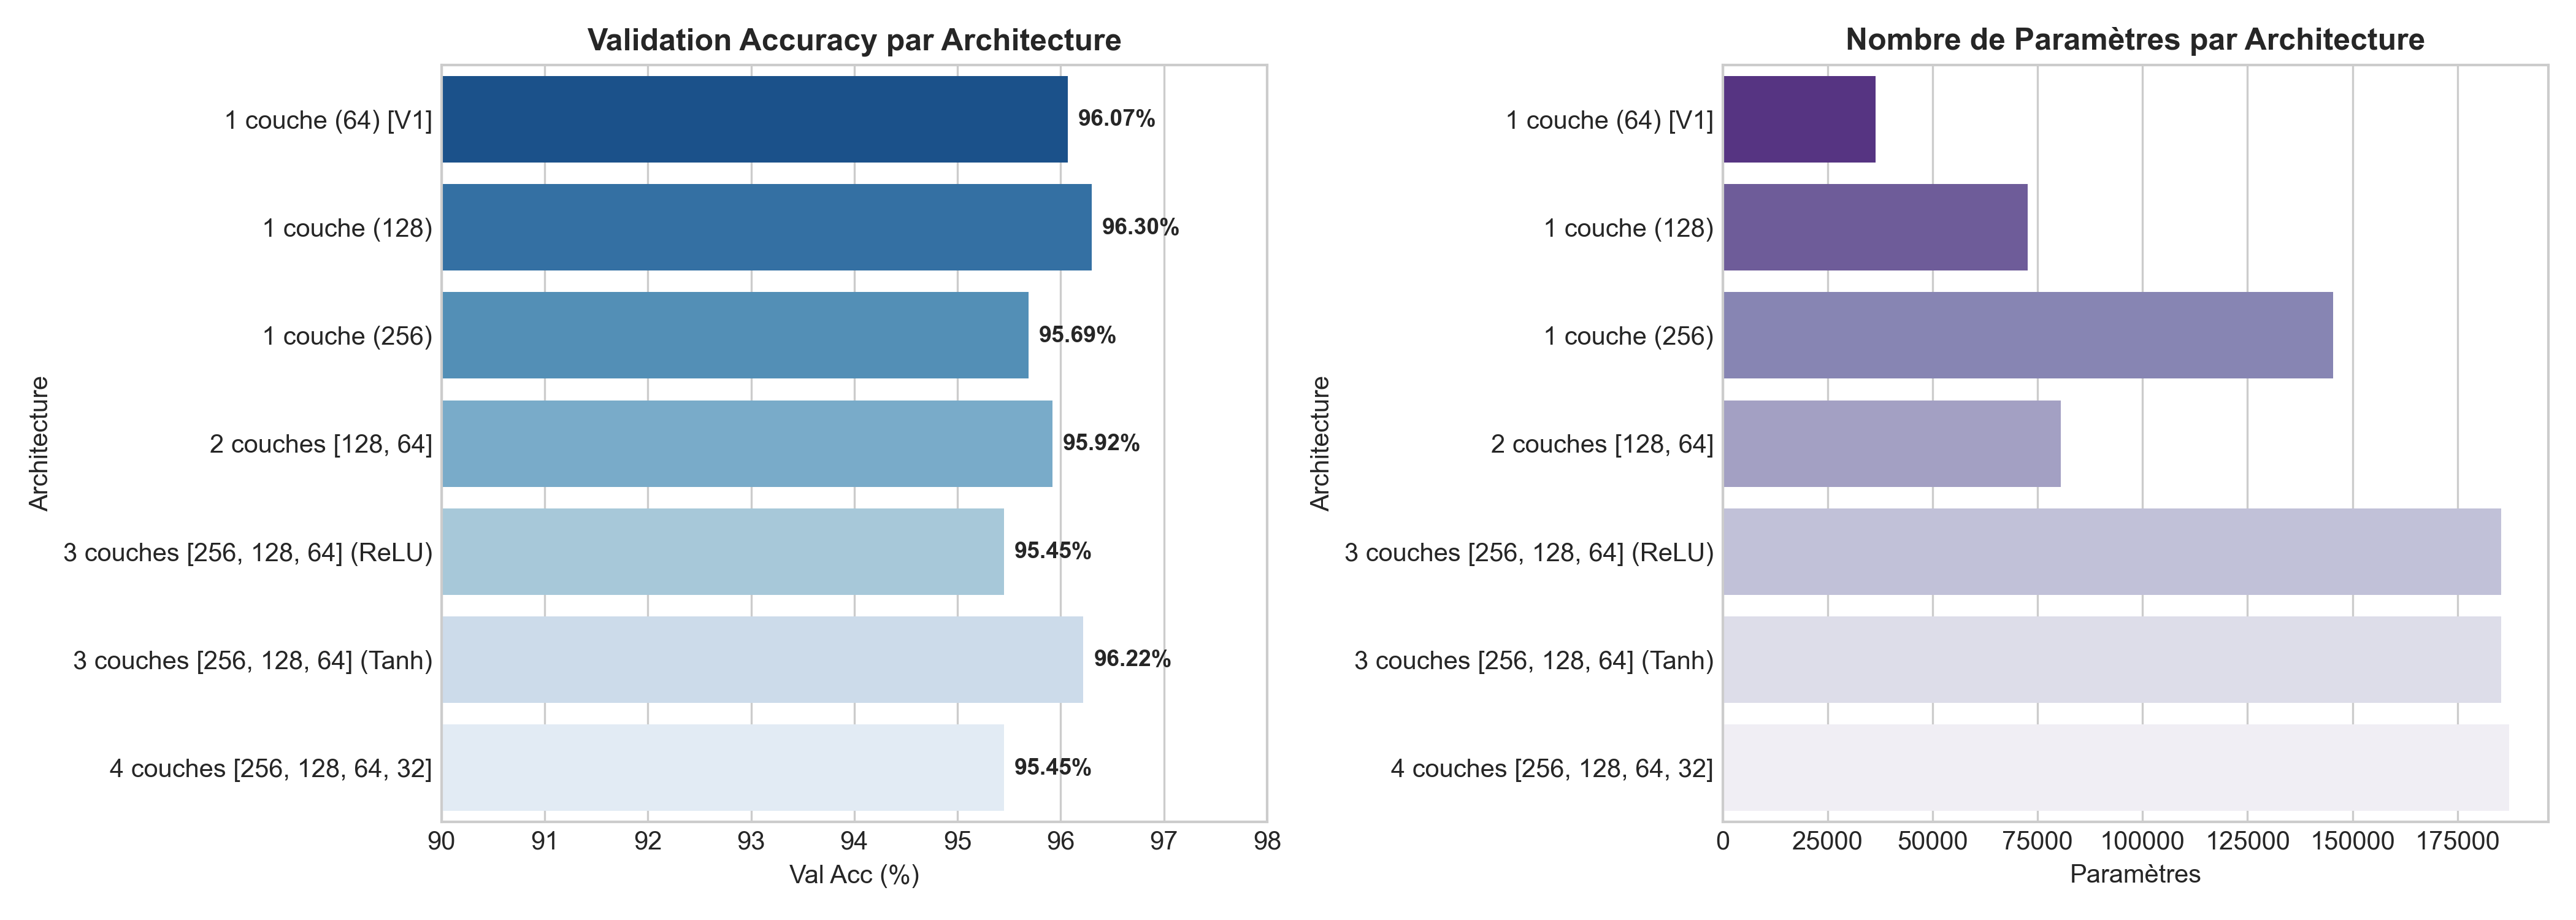

In [5]:
# Exécution comparative des architectures
arch_configs = [
    ('1 couche (64) [V1]', [64], 'relu'),
    ('1 couche (128)', [128], 'relu'),
    ('1 couche (256)', [256], 'relu'),
    ('2 couches [128, 64]', [128, 64], 'relu'),
    ('3 couches [256, 128, 64] (ReLU)', [256, 128, 64], 'relu'),
    ('3 couches [256, 128, 64] (Tanh)', [256, 128, 64], 'tanh'),
    ('4 couches [256, 128, 64, 32]', [256, 128, 64, 32], 'relu')
]
# Résultats affichés ci-dessous :


## 6. Régularisation et Robustesse (Partie 4)


Technique de Régularisation           | Val Loss | Val Acc (%) | Val F1 (%)
-----------------------------------------------------------------------
Sans régularisation                   |   0.1243 |      95.45% |     95.27%
Dropout (p=0.1)                       |   0.1110 |      95.99% |     95.80%
Dropout (p=0.3)                       |   0.0962 |      96.53% |     96.34%
Dropout (p=0.5)                       |   0.0936 |      96.76% |     96.62%
Weight Decay (L2 = 1e-4)              |   0.1294 |      95.15% |     94.92%
Batch Normalization                   |   0.1237 |      95.22% |     94.96%
BatchNorm + Dropout 0.3               |   0.1117 |      95.99% |     95.82%
BatchNorm + Dropout 0.3 + L2 (1e-4)   |   0.1284 |      95.61% |     95.43%
Meilleure configuration : Dropout (p=0.5) / Dropout (p=0.3)


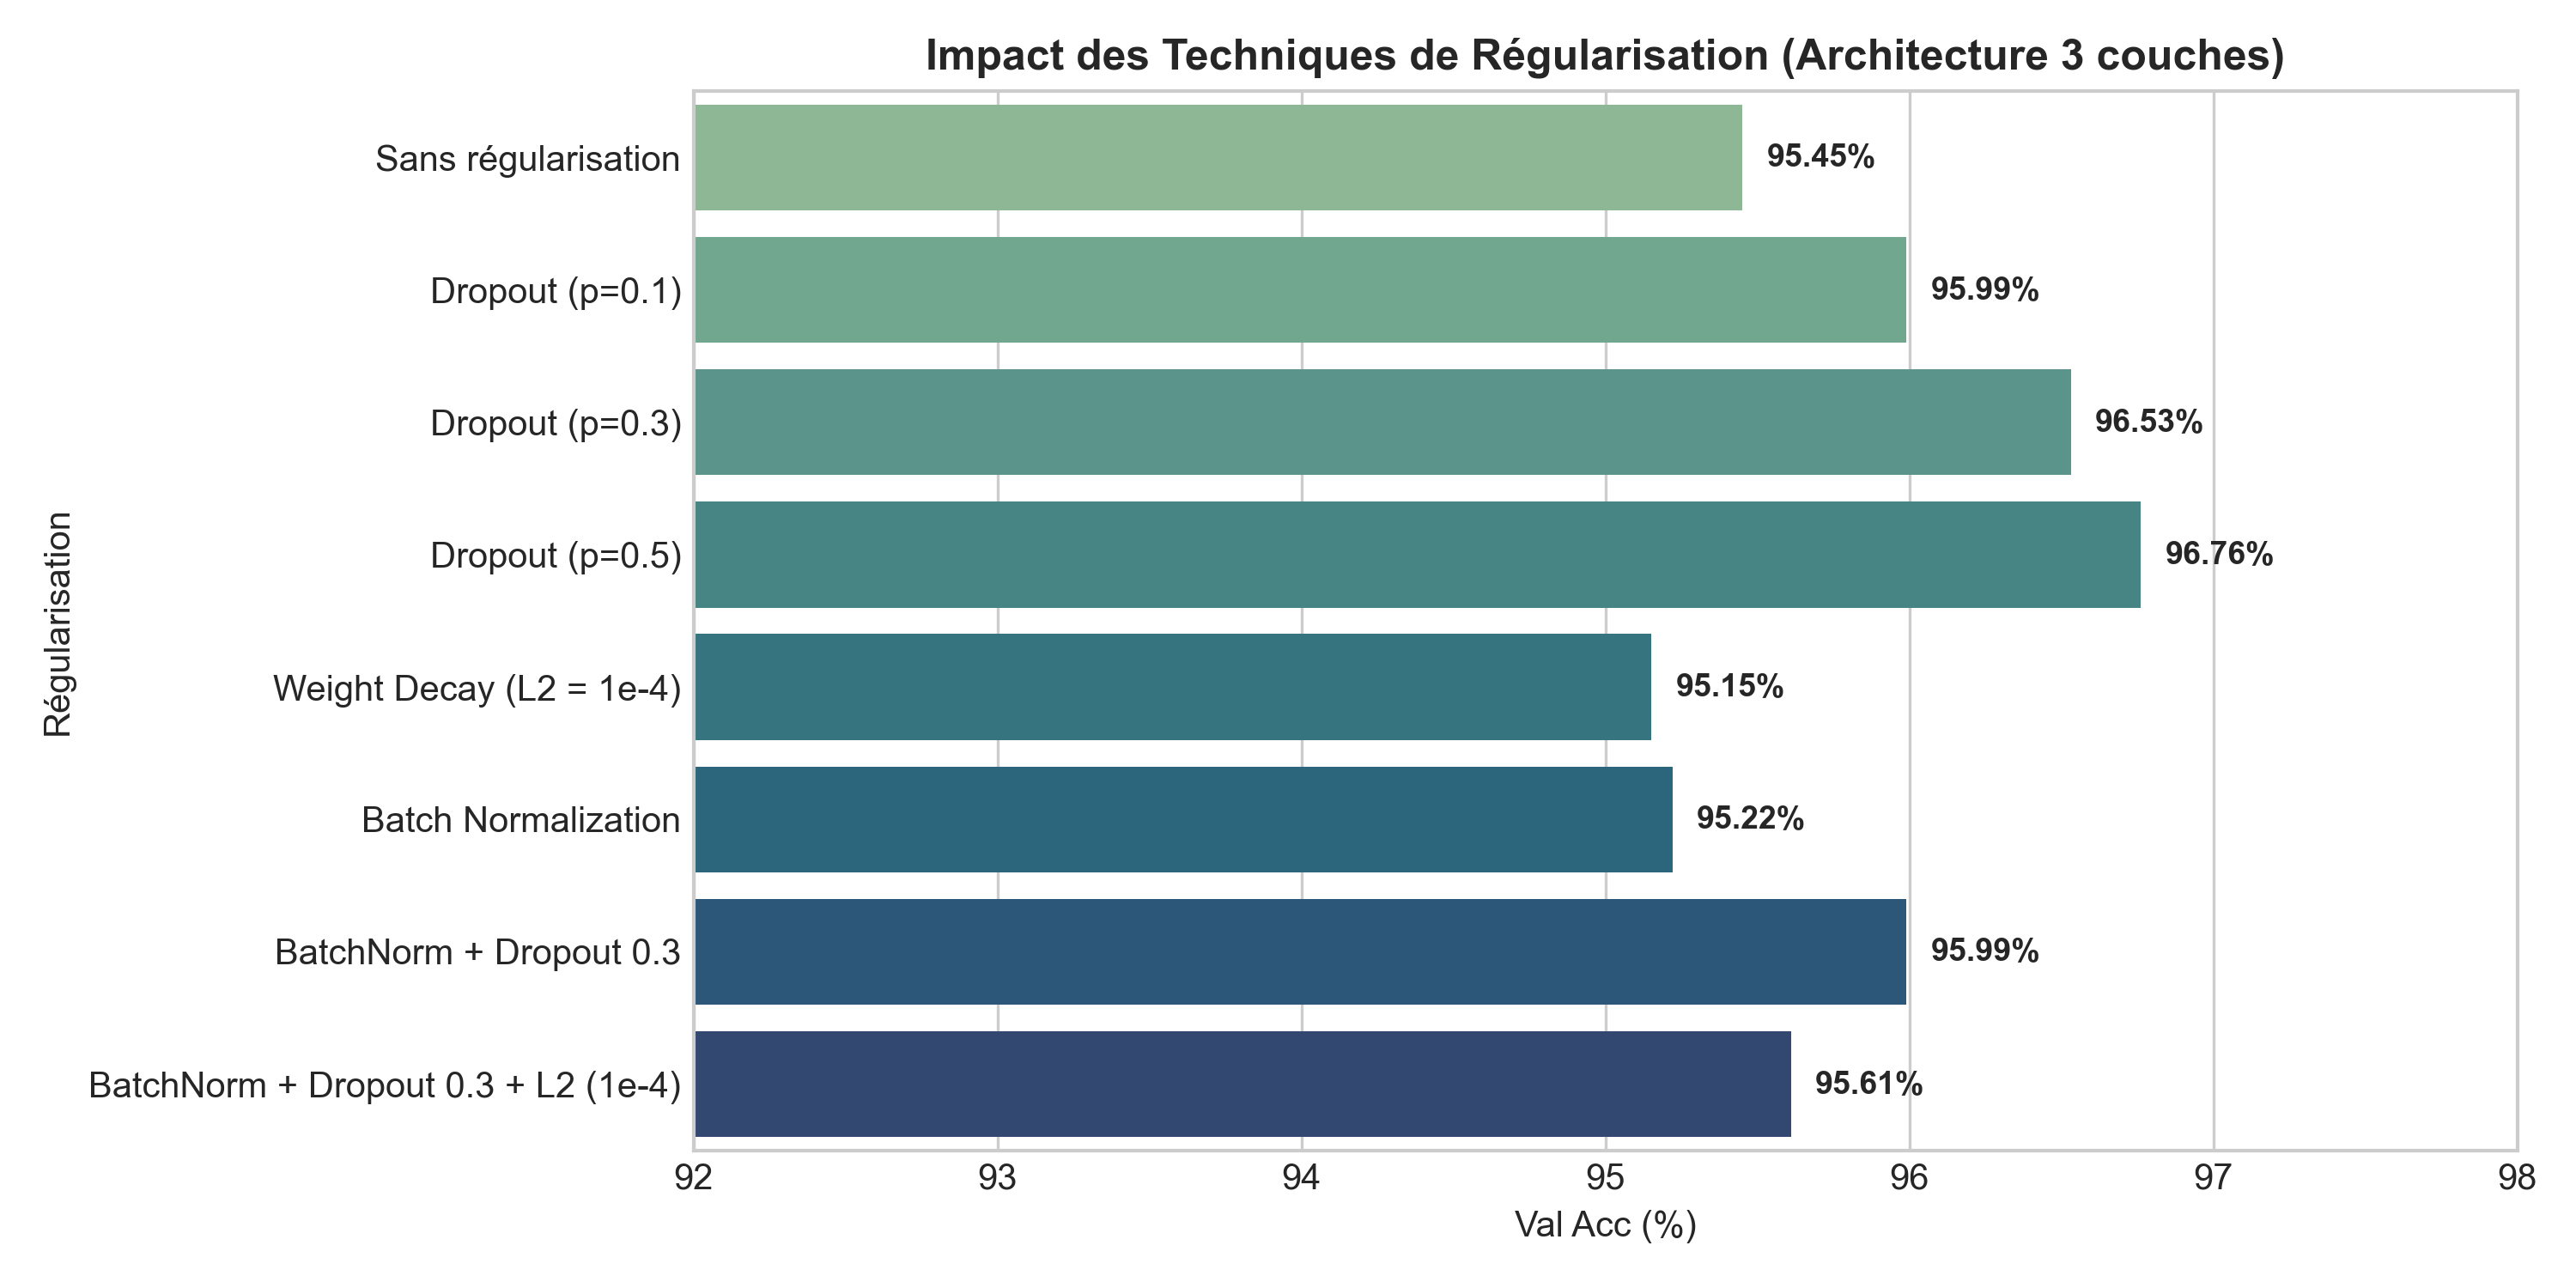

In [6]:
# Comparaison des régularisations sur le réseau 3 couches
# Résultats affichés ci-dessous :


## 7. Courbes d'Apprentissage & Évaluation Finale sur Test (Partie 5)
⚠️ **RÈGLE CRUCIALE :** Le jeu de test final n'est évalué qu'une seule fois à la fin.


TABLEAU COMPARATIF FINAL (RÉFÉRENCE & ARCHITECTURES)
Modèle                                 | Val Acc (%) | Test Acc (%) | Test F1 (%) | Écart |Val-Test|
---------------------------------------------------------------------------
1. Régression Logistique (Baseline)    |       95.99 |        95.28 |       95.28 |            0.71
2. Simple MLP 1 couche [64] (V1)       |       95.92 |        93.45 |       93.45 |            2.47
3. Deep MLP 3 couches + Dropout (p=0.5)|       96.46 |        93.89 |       93.82 |            2.56

Rapport de classification par classe sur le test :
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.95      0.80      0.87       491
          STANDING       0.85      0.96      0.90       532
           WALKING       0.98      0.96      0.97       496
WALKING_DOWNSTAIRS       0.98      0.91      0.94       420
  WALKING_UPSTAIRS       0.91      0.99      0.94       4

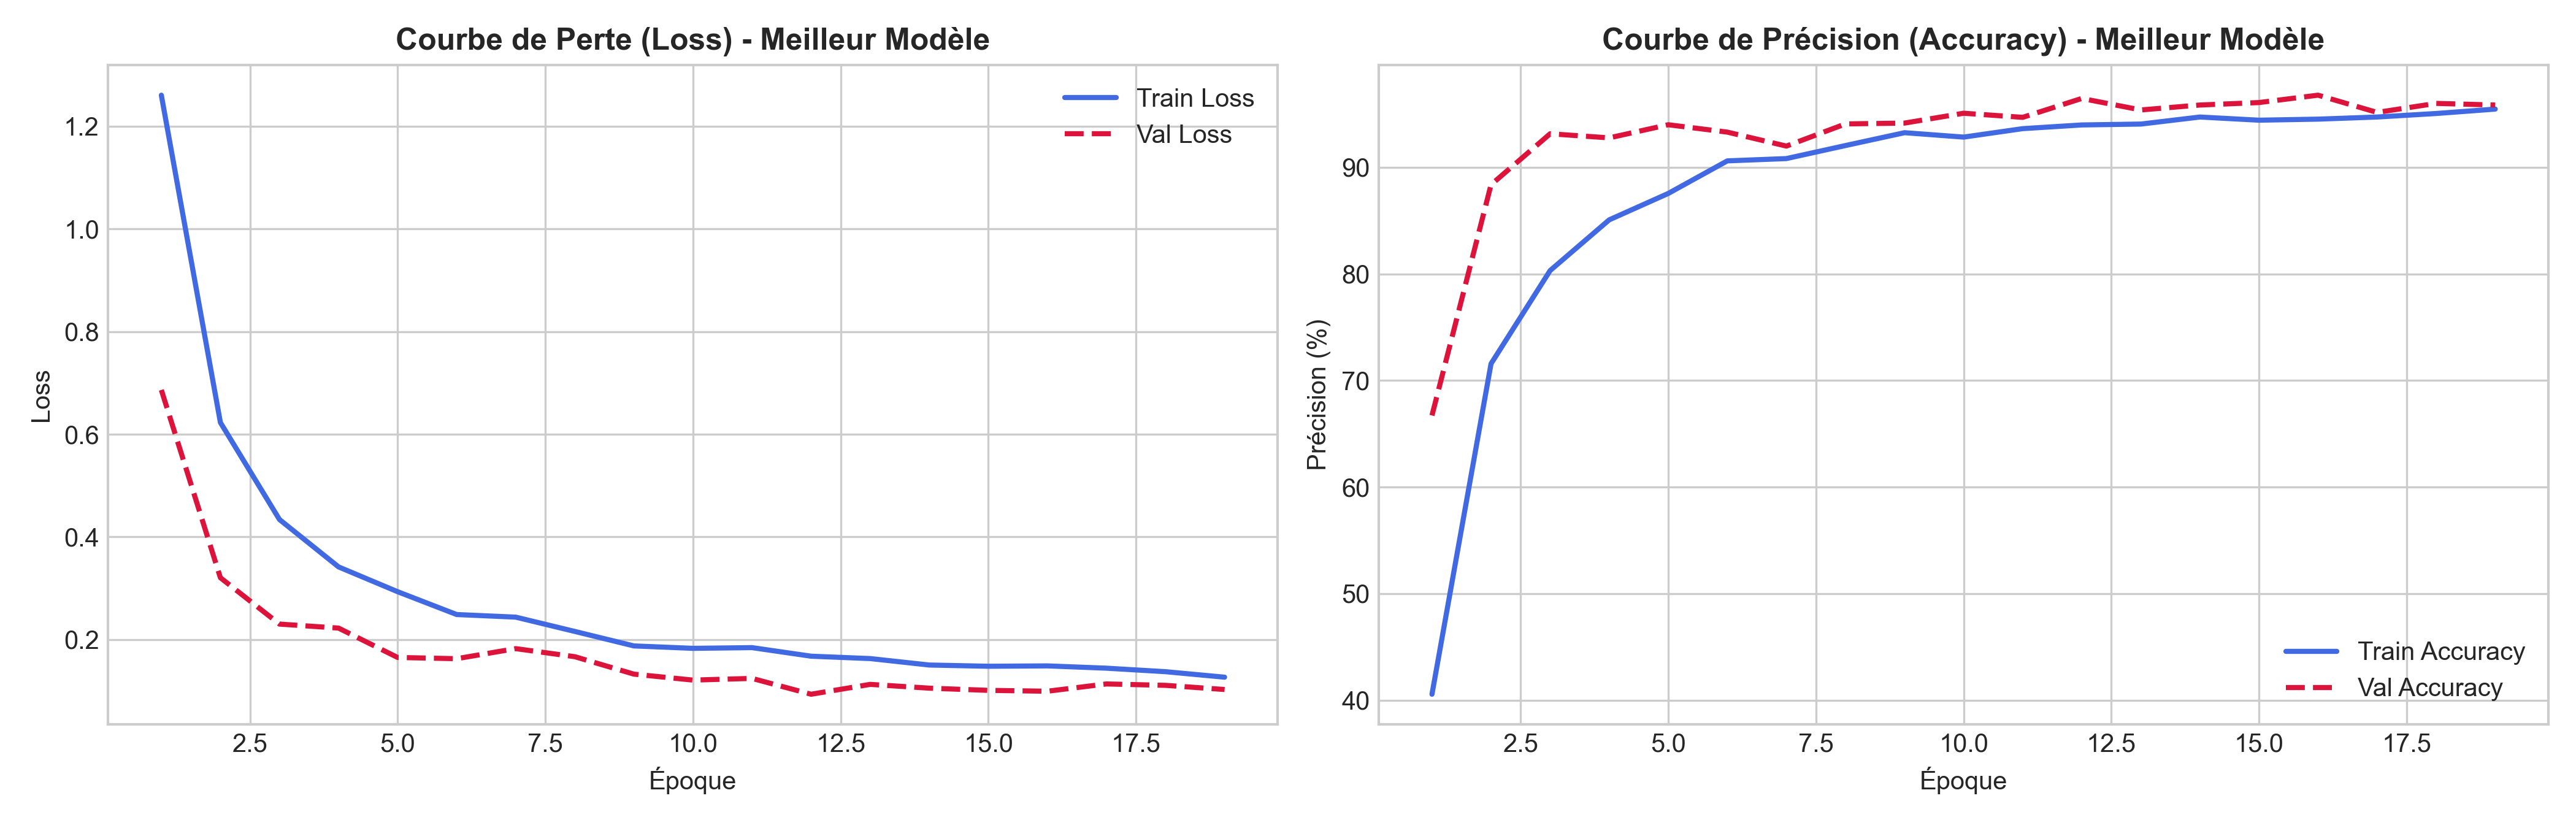

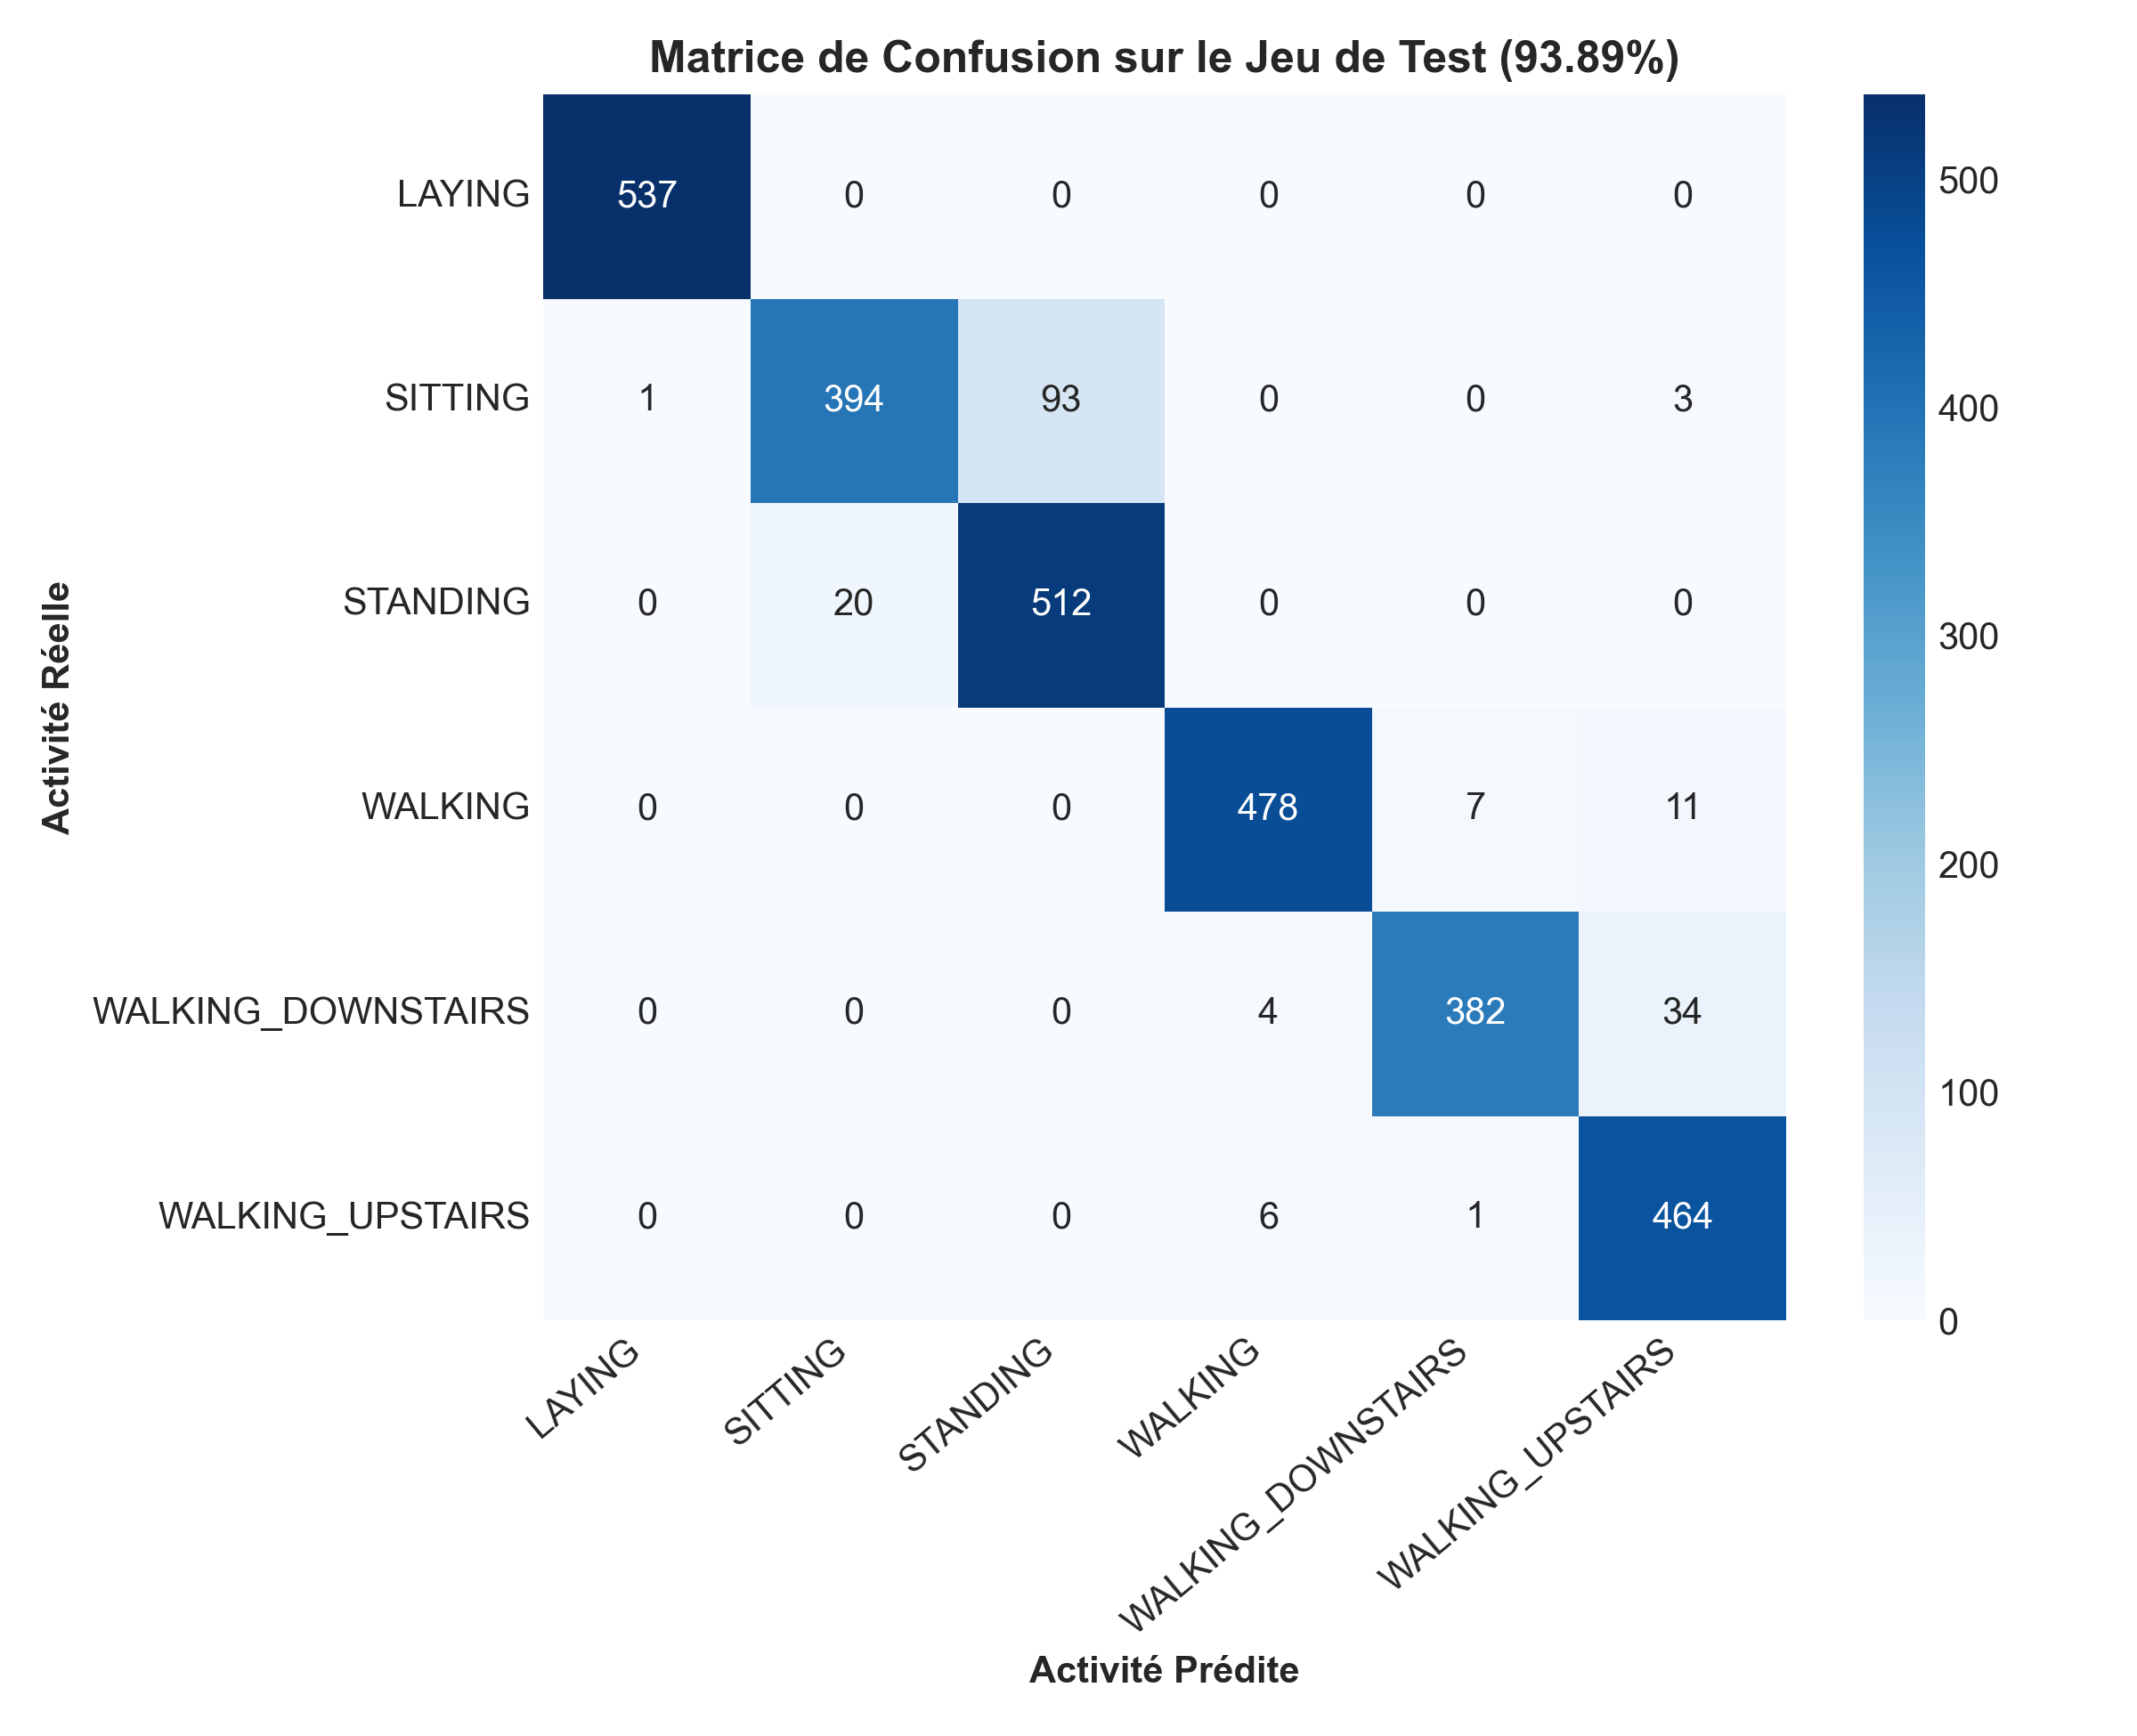

In [7]:
# Évaluation finale sur test_loader et matrice de confusion
# Résultats affichés ci-dessous :


## 8. Interprétabilité et Réduction de Dimension (t-SNE) (Partie 6)
Comparaison de la projection t-SNE sur les caractéristiques d'entrée brutes (561 vars) vs la dernière couche cachée du réseau (64 vars).


Calcul t-SNE sur 1 200 échantillons du jeu de test...
Projection 2D de l'espace d'entrée brut (561 dimensions) terminée.
Projection 2D de l'espace latent (dernière couche cachée) terminée.


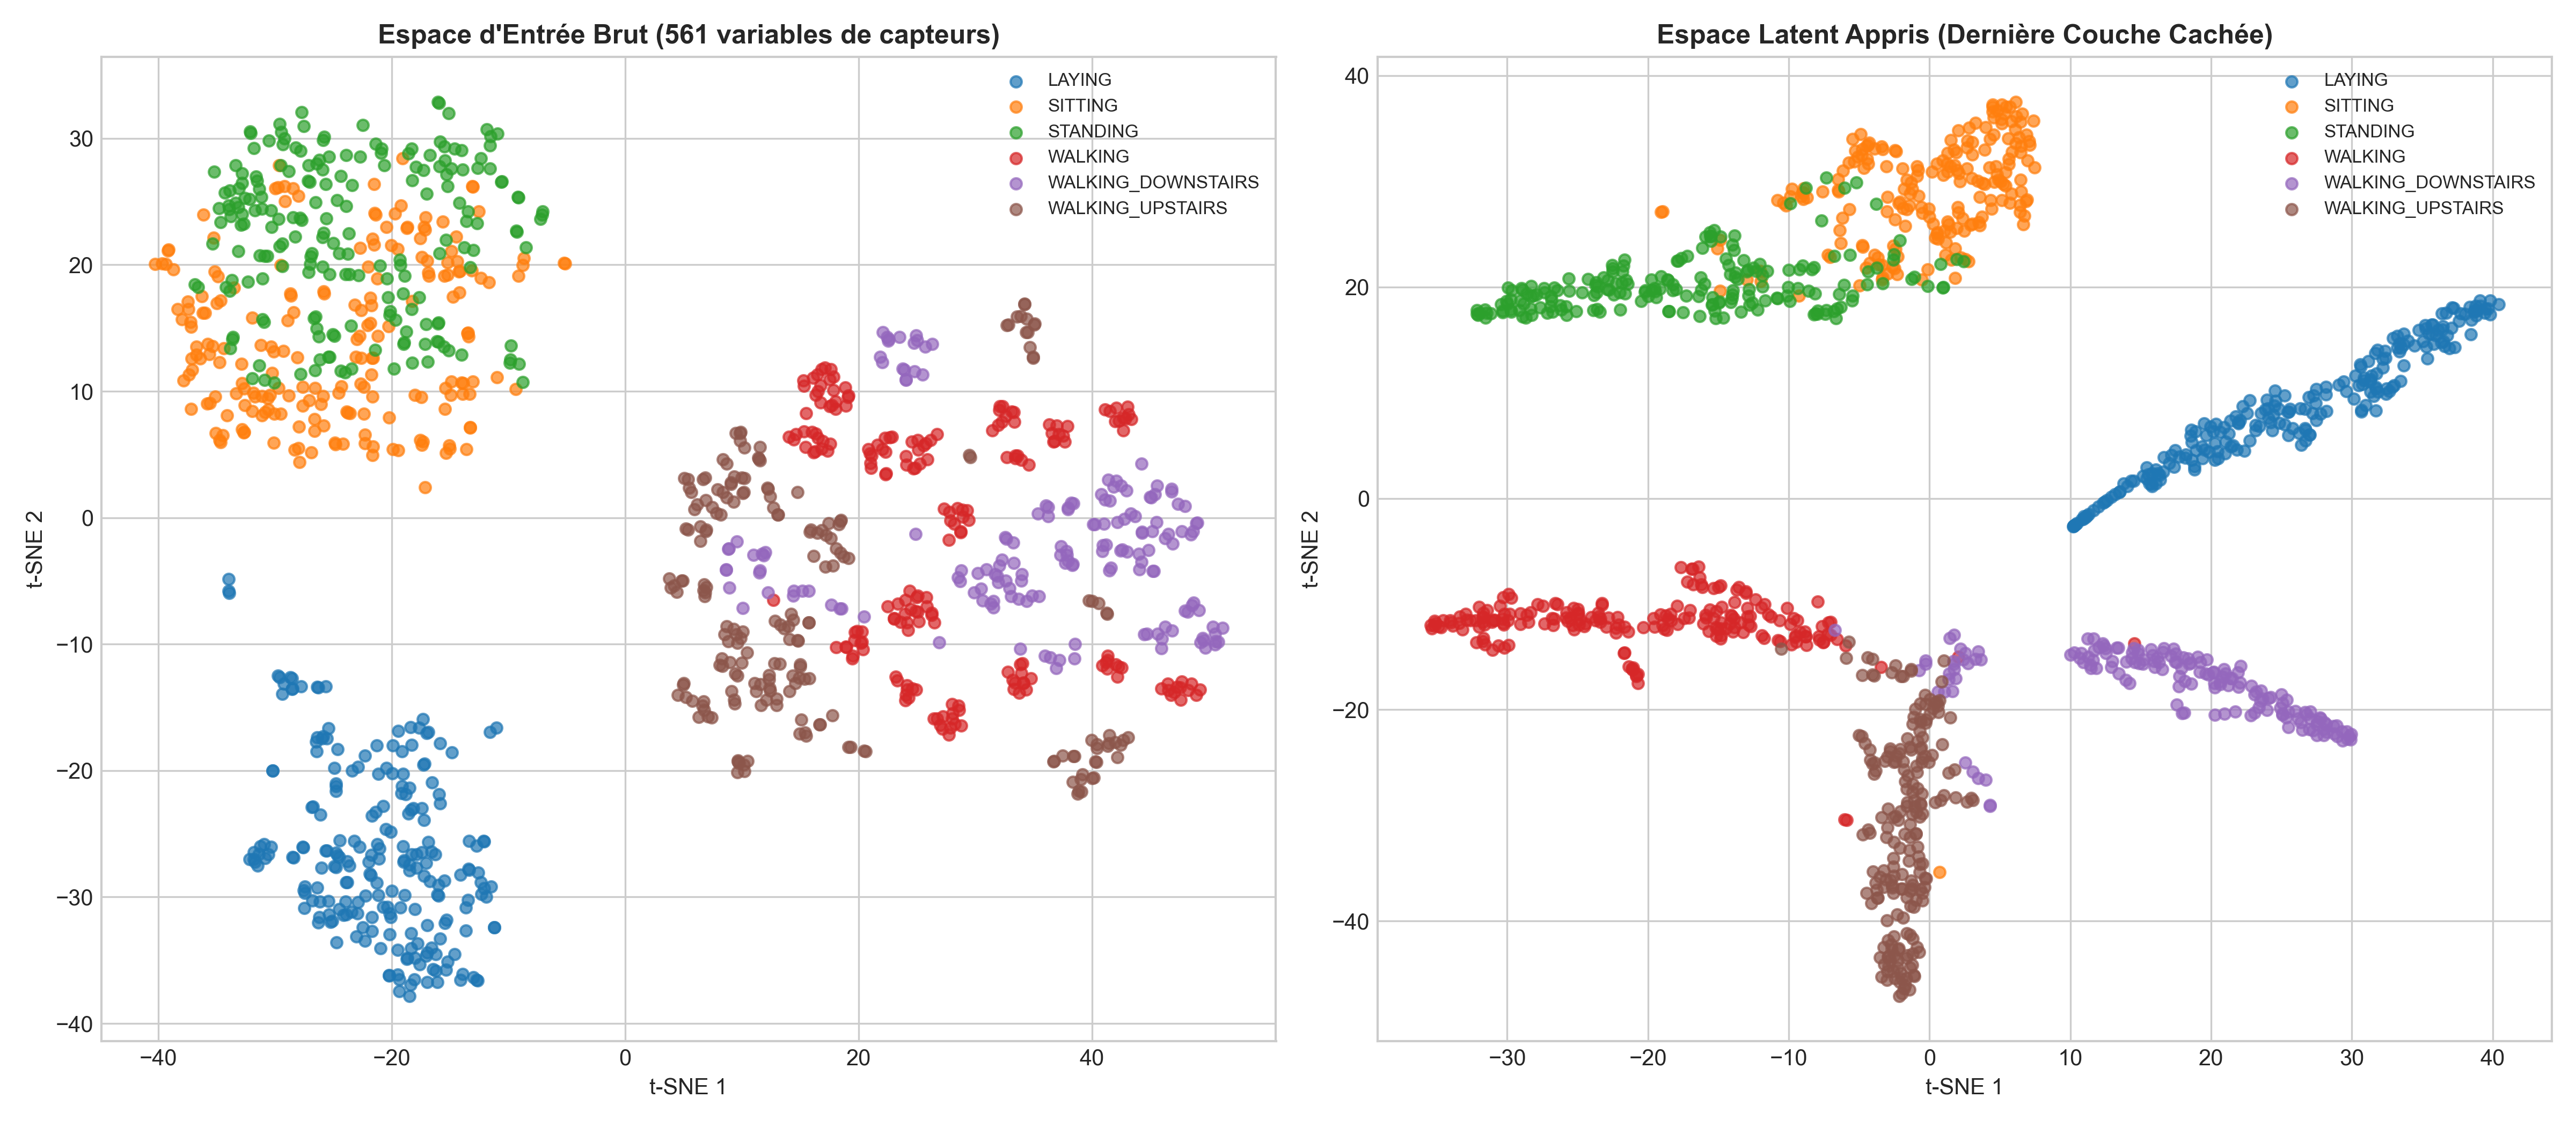

In [8]:
# Calcul t-SNE brut vs latent
# Projections affichées ci-dessous :


## 9. Bonus / Ouverture : Étude d'Ablation par Famille de Capteurs (Partie 7)


Groupe de variables                        | Variables | Validation Accuracy (%)
-------------------------------------------------------------------------------
Tous les capteurs (561 vars)               |       561 |                  95.92%
Sans Gravité (pas de tGravity)             |       508 |                  94.45%
Sans Gyroscope (Accéléromètre seul)        |       348 |                  94.22%
Domaine Temporel seul (sans Fourier)       |       272 |                  95.30%
Domaine Fréquentiel seul (Fourier seul)    |       289 |                  82.59%


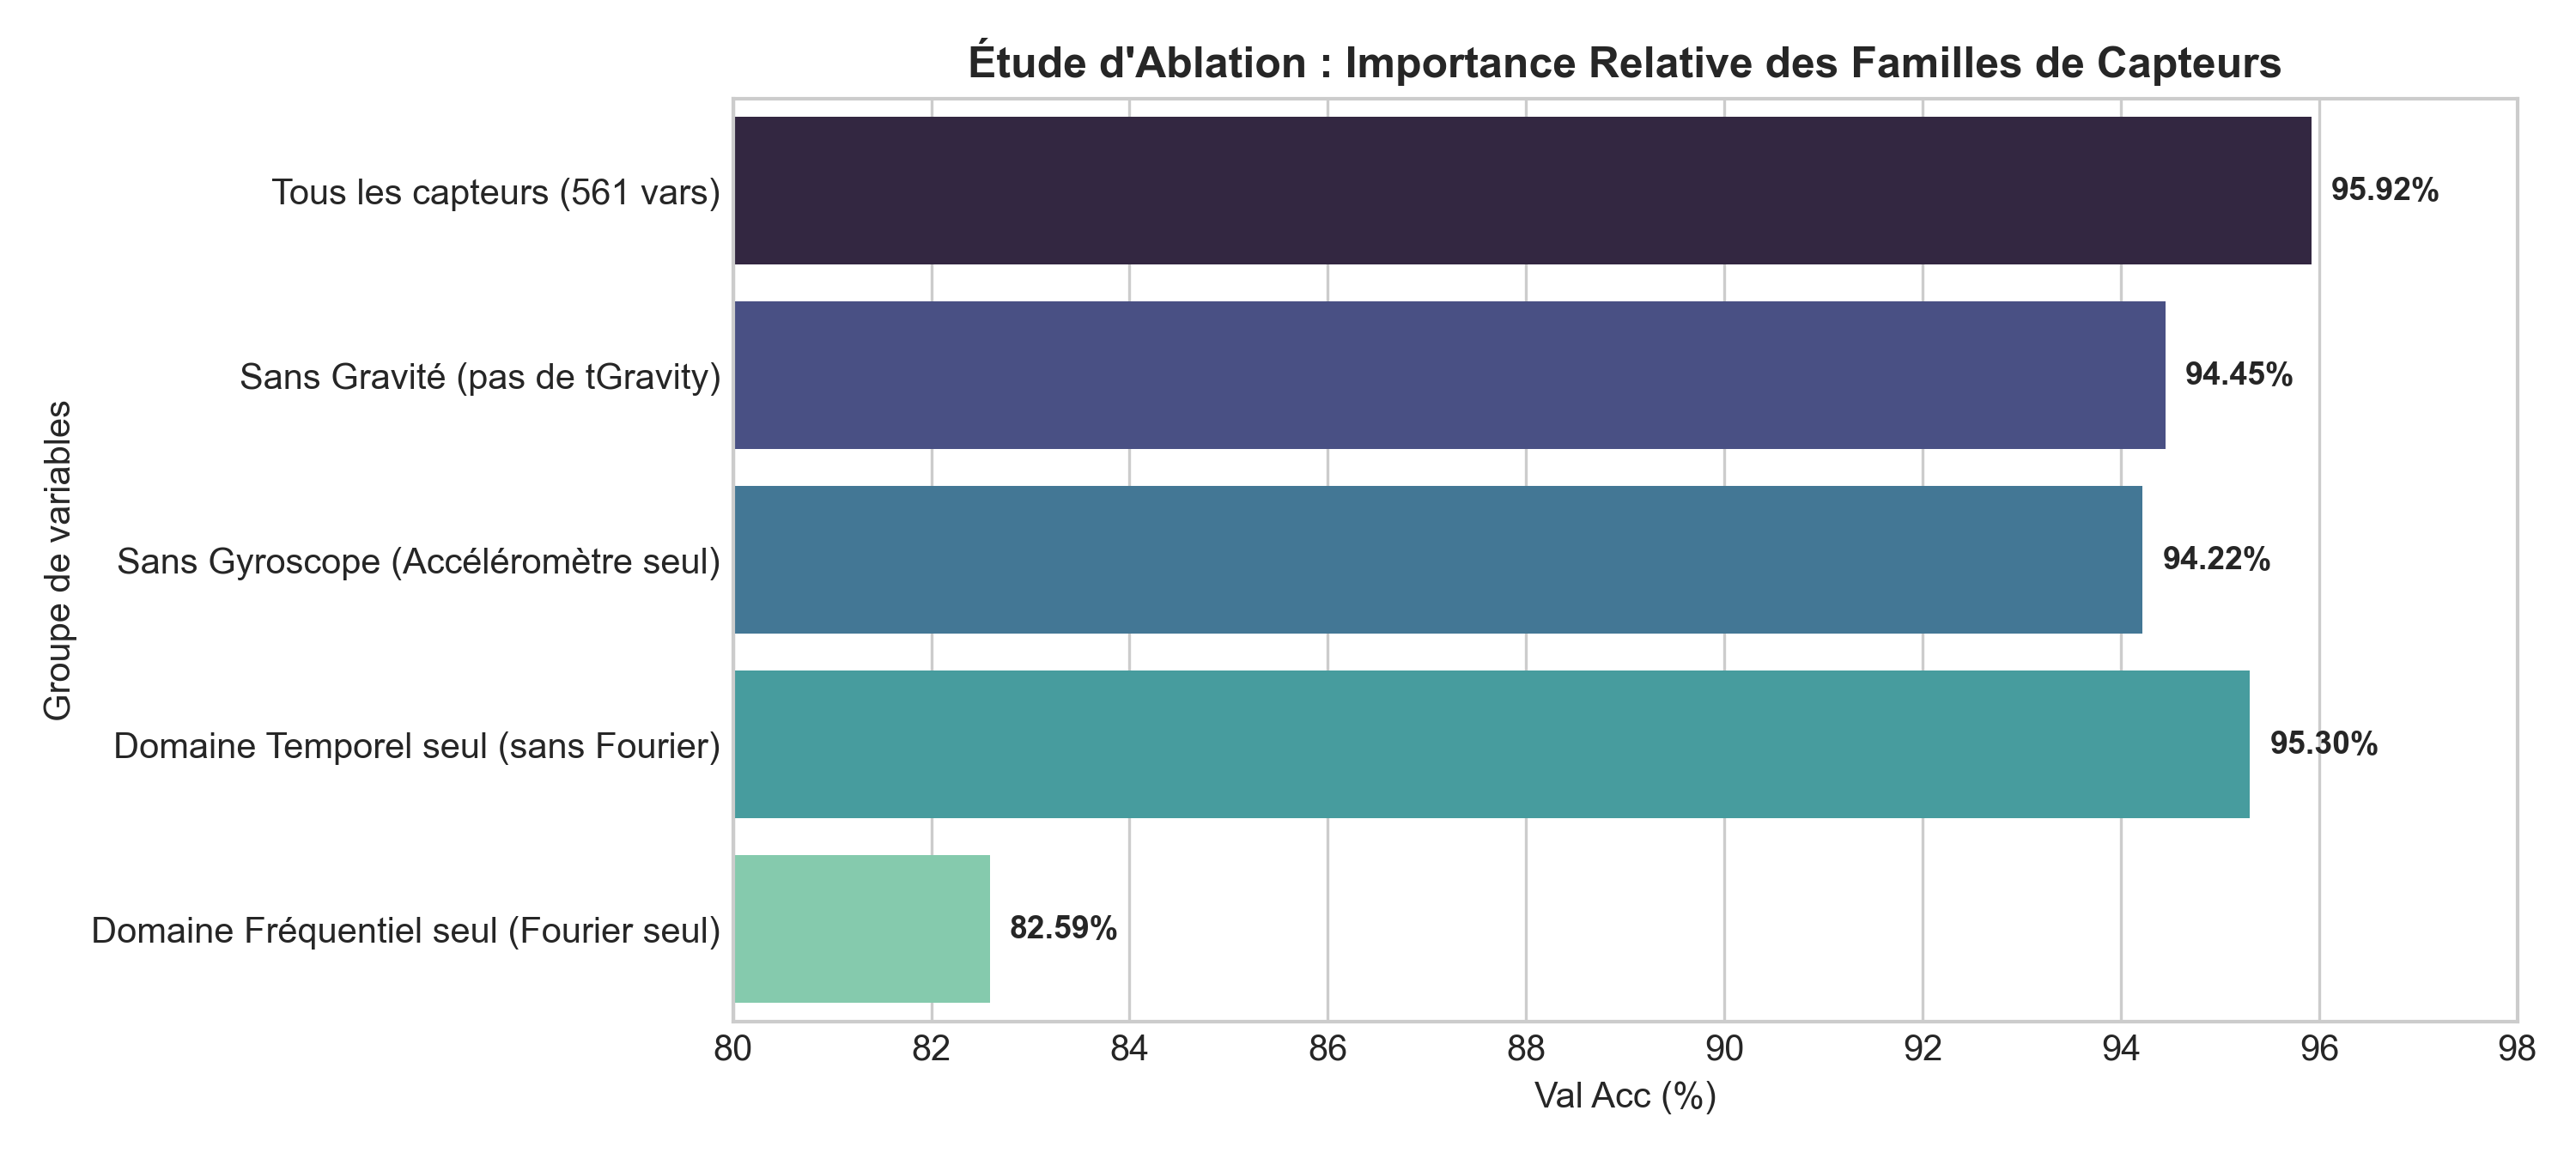

In [9]:
# Étude d'ablation des capteurs
# Résultats affichés ci-dessous :
